
#### Celda 1 (Markdown): Introducción Teórica

In [1]:
%%markdown
# Laboratorio Académico: Selección de Clústeres Óptimos con el Método del Codo
En este notebook analizaremos cómo determinar el hiperparámetro $k$ en K-Means mediante:
1. Generación de un espacio multidimensional sintético con agrupaciones bien delimitadas.
2. Estandarización de variables ($Z$-score) para preservar las métricas de distancia euclidiana.
3. Evaluación iterativa de la Inercia (Within-Cluster Sum of Squares - WCSS).
4. Localización del punto de inflexión ("codo") y validación mediante Silhouette Score.

# Laboratorio Académico: Selección de Clústeres Óptimos con el Método del Codo
En este notebook analizaremos cómo determinar el hiperparámetro $k$ en K-Means mediante:
1. Generación de un espacio multidimensional sintético con agrupaciones bien delimitadas.
2. Estandarización de variables ($Z$-score) para preservar las métricas de distancia euclidiana.
3. Evaluación iterativa de la Inercia (Within-Cluster Sum of Squares - WCSS).
4. Localización del punto de inflexión ("codo") y validación mediante Silhouette Score.


#### Celda 2 (Código): Importación de Librerías y Configuración

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración visual para mantener fondos claros y figuras de alta resolución
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

#### Celda 3 (Código): Generación y Estandarización de Datos

In [3]:
# Generamos 600 observaciones sintéticas agrupadas intencionalmente en 4 centros
# X contiene las variables explicativas continuas; ignoramos y_true (no supervisado)
X_raw, y_true = make_blobs(
    n_samples=600,
    n_features=2,
    centers=4,
    cluster_std=0.75,
    random_state=42
)

# REGLA METODOLÓGICA: Como K-means calcula distancias euclidianas,
# es mandatorio estandarizar los atributos para evitar que una escala domine el coste.
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f"Dimensiones de la matriz de entrada X: {X.shape}")

Dimensiones de la matriz de entrada X: (600, 2)


#### Celda 4 (Código): Ejecución del Bucle de Inercia

In [4]:
# Evaluamos un rango de k desde 1 hasta 10 clústeres
k_candidatos = range(1, 11)
inercias = []
coeficientes_silueta = []

for k in k_candidatos:
    # Usamos init='k-means++' para optimizar la dispersión inicial de los centroides
    km = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )
    km.fit(X)
    
    # La inercia calculada (WCSS) queda almacenada en el atributo km.inertia_
    inercias.append(km.inertia_)
    
    # El coeficiente de silueta solo está definido formalmente para k >= 2
    if k >= 2:
        score_sil = silhouette_score(X, km.labels_)
        coeficientes_silueta.append(score_sil)
    else:
        coeficientes_silueta.append(None)

# Resumen tabular de la evaluación
df_evaluacion = pd.DataFrame({
    'k': list(k_candidatos),
    'Inercia (WCSS)': inercias,
    'Silhouette Score': coeficientes_silueta
})
display(df_evaluacion)

,k,Inercia (WCSS),Silhouette Score
0,1,1200.000000,NaN
1,2,624.522982,0.572866
2,3,131.708550,0.768589
3,4,20.445476,0.847178
4,5,18.468749,0.718629
5,6,16.666999,0.589216
6,7,14.810441,0.448872
7,8,12.996006,0.330489
8,9,11.861457,0.335413
9,10,10.803729,0.349099


#### Celda 5 (Código): Graficación de la Curva del Codo (Elbow Curve)

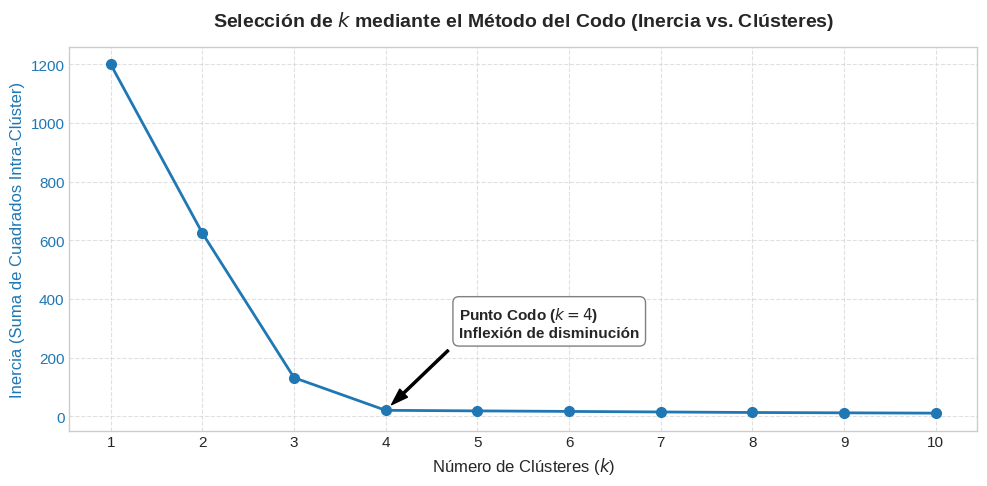

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5), facecolor='white')

# Curva principal de Inercia
color_inercia = '#1f77b4'
ax1.plot(k_candidatos, inercias, marker='o', color=color_inercia, linewidth=2, markersize=7)
ax1.set_title('Selección de $k$ mediante el Método del Codo (Inercia vs. Clústeres)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Número de Clústeres ($k$)', fontsize=12)
ax1.set_ylabel('Inercia (Suma de Cuadrados Intra-Clúster)', color=color_inercia, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_inercia)
ax1.set_xticks(list(k_candidatos))
ax1.grid(True, linestyle='--', alpha=0.6)

# Anotación pedagógica en el punto de codo esperado (k=4)
punto_codo_k = 4
inercia_codo = inercias[punto_codo_k - 1]
ax1.annotate(
    f'Punto Codo ($k={punto_codo_k}$)\nInflexión de disminución',
    xy=(punto_codo_k, inercia_codo),
    xytext=(punto_codo_k + 0.8, inercia_codo + 250),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
    fontsize=11,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", lw=1)
)

plt.tight_layout()
plt.show()

#### Celda 6 (Código): Validación Visual del Clúster Óptimo Obtenido

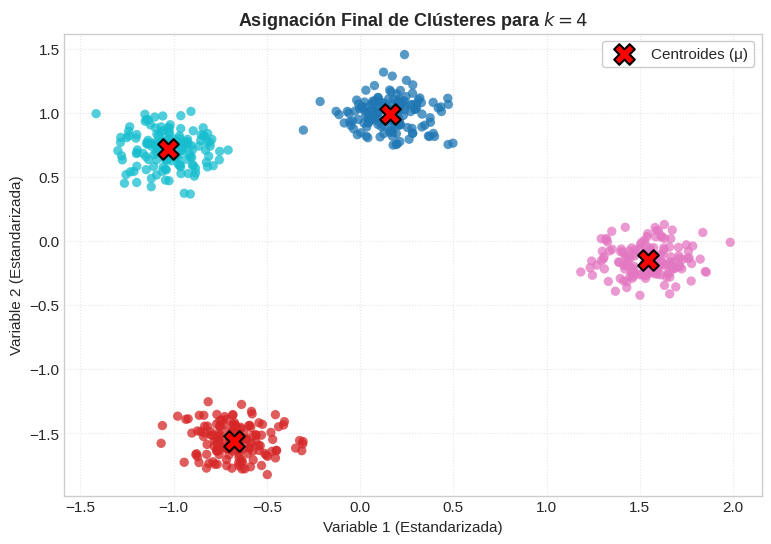

In [6]:
# Entrenamos el modelo definitivo configurado en k=4
k_optimo = 4
modelo_final = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
etiquetas_finales = modelo_final.fit_predict(X)
centroides = modelo_final.cluster_centers_

# Visualización del particionamiento y centroides resultantes
plt.figure(figsize=(9, 6), facecolor='white')
scatter = plt.scatter(
    X[:, 0], X[:, 1],
    c=etiquetas_finales,
    cmap='tab10',
    s=45,
    alpha=0.75,
    edgecolors='none'
)

# Graficamos la posición de los centroides calculados
plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker='X',
    s=220,
    c='red',
    edgecolors='black',
    linewidths=1.5,
    label='Centroides (\u03bc)'
)

plt.title(f'Asignación Final de Clústeres para $k={k_optimo}$', fontsize=13, fontweight='bold')
plt.xlabel('Variable 1 (Estandarizada)', fontsize=11)
plt.ylabel('Variable 2 (Estandarizada)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=1)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()